# Race pace & tyre strategy simulator

A model that learns how lap time changes over a stint, trained on the first five races of 2026. I then use it to simulate one-stop strategies and find the best lap to pit.

**Steps**
1. Load clean green-flag laps and remove the effect of fuel load.
2. Look at tyre degradation per compound.
3. Train a lap-time model (XGBoost) and test it on a race it hasn't seen (Canada).
4. Simulate strategies lap by lap and search for the optimal pit lap.
5. Predict the best strategy for every driver at Monaco.

**Data:** 2026 rounds 1–5 (Australia, China, Japan, Miami, Canada), loaded with [FastF1](https://github.com/theOehrly/Fast-F1).

## 1. Setup

In [1]:
%pip install -q fastf1 xgboost

import logging
import tempfile
import warnings

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import LabelEncoder

logging.getLogger('fastf1').setLevel(logging.WARNING)   # keep warnings: failed downloads show up here
warnings.filterwarnings('ignore')

# No local cache: the data is downloaded on every run and nothing is kept on disk.
# FastF1 needs some cache folder configured, otherwise it creates its default one (~1 GB) and
# prints its full path, so it gets an empty temporary folder and the cache is switched off.
fastf1.Cache.enable_cache(tempfile.mkdtemp())
fastf1.Cache.set_disabled()

FUEL_EFFECT_PER_LAP = 0.075   # s per lap gained as fuel burns off (common rule of thumb)
PIT_LOSS = 22.0               # s lost in the pit lane (generic estimate)
ROUNDS = range(1, 6)          # 2026 rounds 1-5
DRY_COMPOUNDS = ['SOFT', 'MEDIUM', 'HARD']

Note: you may need to restart the kernel to use updated packages.


## 2. Loading clean laps

Only representative laps are kept: dry compounds, green flag, no in/out laps, no lap 1, and laps FastF1 marks as accurate.

- **Fuel correction.** A car gets about 0.075 s faster every lap as it burns fuel. Every lap is corrected to its empty-tank equivalent, so what remains is the effect of the tyres.
- **Tyre degradation.** This is how much slower a lap is than the stint's reference pace. The reference is the 25th percentile of the stint: a fast lap, but one the driver can sustain. It ignores the first laps of the stint (3 at the start of the race, 1 after a stop).

In [2]:
def load_race(year, round_num):
    session = fastf1.get_session(year, round_num, 'R')
    session.load(messages=False)

    laps = pd.DataFrame(session.laps)
    total_laps = int(laps['LapNumber'].max())
    # Lap number within the stint, counted before filtering so it follows the real tyre age
    laps['StintLap'] = laps.groupby(['Driver', 'Stint']).cumcount() + 1

    keep = (
        laps['Compound'].isin(DRY_COMPOUNDS)
        & laps['TrackStatus'].eq('1')                            # green flag
        & laps['PitInTime'].isna() & laps['PitOutTime'].isna()   # no in/out laps
        & laps['LapTime'].notna() & laps['Time'].notna()
        & (laps['LapNumber'] > 1)                                # skip the standing start
        & laps['IsAccurate'].eq(True)
    )
    laps = laps[keep].copy()
    laps['LapTime_s'] = laps['LapTime'].dt.total_seconds()
    laps['FuelCorrectedTime'] = laps['LapTime_s'] - (total_laps - laps['LapNumber']) * FUEL_EFFECT_PER_LAP

    skip = np.where(laps['Stint'] == 1, 3, 1)
    ref = (laps[laps['StintLap'] > skip]
           .groupby(['Driver', 'Stint'])['FuelCorrectedTime'].quantile(0.25)
           .rename('RefPace'))
    laps = laps.join(ref, on=['Driver', 'Stint'])
    laps['TyreDeg'] = laps['FuelCorrectedTime'] - laps['RefPace']

    # Attach the closest weather sample to every lap, then drop wet laps
    weather = session.weather_data[['Time', 'TrackTemp', 'AirTemp', 'Humidity', 'Rainfall']]
    laps = pd.merge_asof(laps.sort_values('Time'), weather.sort_values('Time'), on='Time', direction='nearest')
    laps = laps[~laps['Rainfall'].astype(bool)].copy()

    laps['Round'] = round_num
    laps['EventName'] = session.event['EventName']
    laps['TotalLaps'] = total_laps
    print(f"Round {round_num}: {session.event['EventName']} — {len(laps)} laps")
    return laps


df = pd.concat([load_race(2026, r) for r in ROUNDS], ignore_index=True)
print(f"\nTotal: {len(df)} laps from {df['Round'].nunique()} races")

core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 81)
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 27)


Round 1: Australian Grand Prix — 834 laps


core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 81)
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 1)
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 5)
core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 23)
core        WARNING 	Driver 12 completed the race distance 00:00.022000 before the recorded end of the session.
_api        WARNING 	Driver 241: Position data is incomplete!
_api        WARNING 	Driver 242: Position data is incomplete!
_api        WARNING 	Driver 243: Position data is incomplete!


Round 2: Chinese Grand Prix — 738 laps


_api        WARNING 	Driver 241: Position data is incomplete!
_api        WARNING 	Driver 242: Position data is incomplete!
_api        WARNING 	Driver 243: Position data is incomplete!


Round 3: Japanese Grand Prix — 918 laps


core        WARNING 	Driver 12 completed the race distance 00:00.027000 before the recorded end of the session.
_api        WARNING 	Driver 241: Position data is incomplete!
_api        WARNING 	Driver 242: Position data is incomplete!
_api        WARNING 	Driver 243: Position data is incomplete!


Round 4: Miami Grand Prix — 791 laps


core        WARNING 	Failed to perform lap accuracy check - all laps marked as inaccurate (driver 41)


Round 5: Canadian Grand Prix — 934 laps

Total: 4215 laps from 5 races


## 3. Tyre degradation per compound

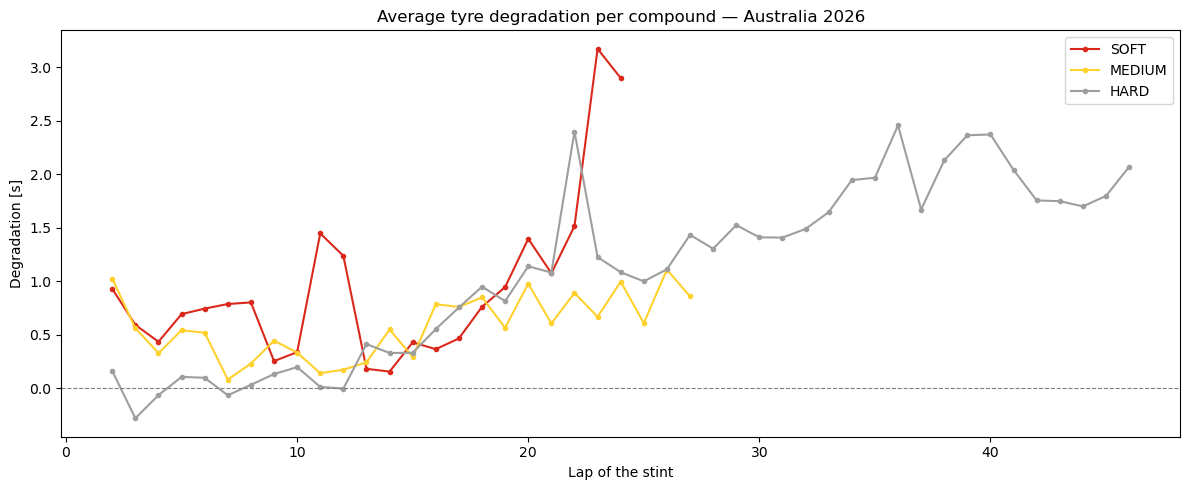

In [3]:
COMPOUND_COLORS = {'SOFT': '#da291c', 'MEDIUM': '#ffd12e', 'HARD': '#9e9e9e'}

aus = df[df['EventName'] == 'Australian Grand Prix']
fig, ax = plt.subplots(figsize=(12, 5))
for compound in DRY_COMPOUNDS:
    curve = aus[aus['Compound'] == compound].groupby('StintLap')['TyreDeg'].mean()
    if not curve.empty:
        ax.plot(curve.index, curve.values, marker='o', markersize=3, label=compound, color=COMPOUND_COLORS[compound])
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xlabel('Lap of the stint')
ax.set_ylabel('Degradation [s]')
ax.set_title('Average tyre degradation per compound — Australia 2026')
ax.legend()
plt.tight_layout()
plt.show()

The hard tyre dips below 0 in its first laps. That is expected: the reference is the 25th percentile of the stint, so the quickest laps on fresh tyres fall under it.

## 4. Lap-time model

**Target.** The fuel-corrected lap time minus the circuit's average, i.e. how much faster or slower than usual a lap is at that circuit.

**Features.** Tyre state (lap of the stint, tyre age, compound, stint number), race progress, driver, team and weather.

Two inputs from the first version are left out on purpose:
- **`TyreDeg`** is computed from the lap time itself, so using it as a feature leaks the answer into the input. In the simulation it would also not be known.
- **The circuit code** is redundant, because the target is already relative to each circuit. For a new circuit like Monaco it would also be meaningless.

The model is trained on rounds 1–4 and tested on Canada. As a baseline, always predicting the circuit's average lap is shown next to it.

In [4]:
le_compound = LabelEncoder().fit(DRY_COMPOUNDS)
le_driver = LabelEncoder().fit(df['Driver'])
le_team = LabelEncoder().fit(df['Team'])

df['Compound_enc'] = le_compound.transform(df['Compound'])
df['Driver_enc'] = le_driver.transform(df['Driver'])
df['Team_enc'] = le_team.transform(df['Team'])
df['FreshTyre'] = df['FreshTyre'].astype(int)
df['Target'] = df['FuelCorrectedTime'] - df.groupby('EventName')['FuelCorrectedTime'].transform('mean')

FEATURES = ['StintLap', 'TyreLife', 'LapNumber', 'Stint', 'Compound_enc', 'Driver_enc', 'Team_enc',
            'TrackTemp', 'AirTemp', 'Humidity', 'FreshTyre']
data = df.dropna(subset=FEATURES + ['Target'])


def make_model():
    return xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5,
                            subsample=0.8, colsample_bytree=0.8, random_state=42)


train, test = data[data['Round'] < 5], data[data['Round'] == 5]
model = make_model().fit(train[FEATURES], train['Target'])
pred = model.predict(test[FEATURES])

print(f"MAE on Canada:             {mean_absolute_error(test['Target'], pred):.3f} s")
print(f"Baseline (circuit average): {mean_absolute_error(test['Target'], np.zeros(len(test))):.3f} s")

MAE on Canada:             1.216 s
Baseline (circuit average): 1.384 s


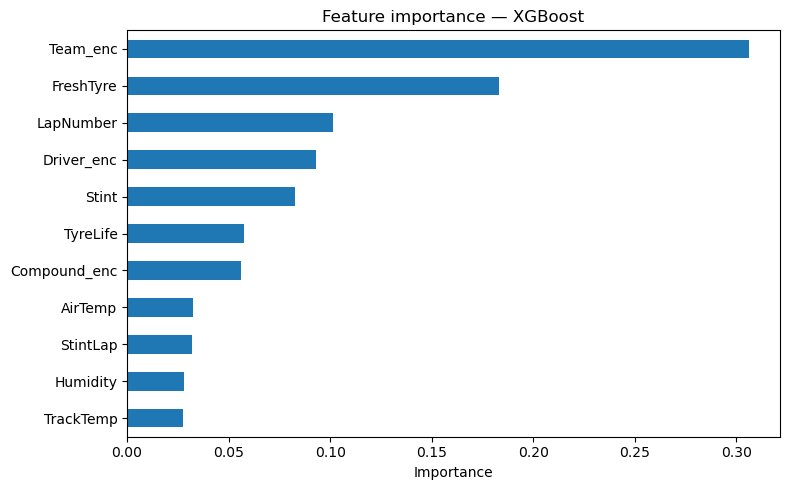

In [5]:
importances = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind='barh', ax=ax)
ax.set_title('Feature importance — XGBoost')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

## 5. Strategy simulator

For the simulation, the model is retrained on all five races. A strategy is simulated lap by lap: the model predicts every lap from the tyre state at that point. The fuel effect is added back so the totals look like real race times, and every stop costs `PIT_LOSS` seconds. All laps of a strategy are predicted in one batch.

**Pit-lap search.** The search tries every pit lap between 30 % and 70 % race distance. Both stints have to stay within a realistic maximum length for their compound; the first version checked only the first stint.

In [6]:
model = make_model().fit(data[FEATURES], data['Target'])
driver_team = df.drop_duplicates('Driver').set_index('Driver')['Team']

MAX_STINT = {'SOFT': 33, 'MEDIUM': 50, 'HARD': 70}   # longest realistic stint per compound
PIT_WINDOW = (0.3, 0.7)                              # fraction of race distance
COMPOUND_PAIRS = [['SOFT', 'MEDIUM'], ['SOFT', 'HARD'], ['MEDIUM', 'HARD']]


def race_params(event_name):
    # Race length, average weather and baseline pace of a race in the dataset
    r = df[df['EventName'] == event_name]
    return dict(total_laps=int(r['TotalLaps'].iloc[0]), track_temp=r['TrackTemp'].mean(),
                air_temp=r['AirTemp'].mean(), humidity=r['Humidity'].mean(),
                baseline=r['FuelCorrectedTime'].mean())


def simulate_strategy(driver, compounds, pit_laps, race):
    # Total race time; a stop on lap p means new tyres from lap p + 1
    n = race['total_laps']
    laps = np.arange(1, n + 1)
    stint = np.searchsorted(pit_laps, laps)           # stint index (0, 1, ...) of every lap
    stint_lap = laps - np.r_[0, pit_laps][stint]

    X = pd.DataFrame({
        'StintLap': stint_lap, 'TyreLife': stint_lap, 'LapNumber': laps, 'Stint': stint + 1,
        'Compound_enc': le_compound.transform(np.array(compounds)[stint]),
        'Driver_enc': le_driver.transform([driver])[0],
        'Team_enc': le_team.transform([driver_team[driver]])[0],
        'TrackTemp': race['track_temp'], 'AirTemp': race['air_temp'], 'Humidity': race['humidity'],
        'FreshTyre': 1,
    })[FEATURES]

    fuel = (n - laps) * FUEL_EFFECT_PER_LAP
    lap_times = model.predict(X) + race['baseline'] + fuel
    return lap_times.sum() + len(pit_laps) * PIT_LOSS


def pit_lap_curve(driver, compounds, race):
    # Total race time for every allowed pit lap of a one-stop strategy
    n = race['total_laps']
    first, second = compounds
    lo = max(int(n * PIT_WINDOW[0]), n - MAX_STINT[second])
    hi = min(int(n * PIT_WINDOW[1]), MAX_STINT[first])
    return pd.Series({pit: simulate_strategy(driver, compounds, [pit], race) for pit in range(lo, hi + 1)},
                     dtype=float)

### Example: Leclerc in Australia

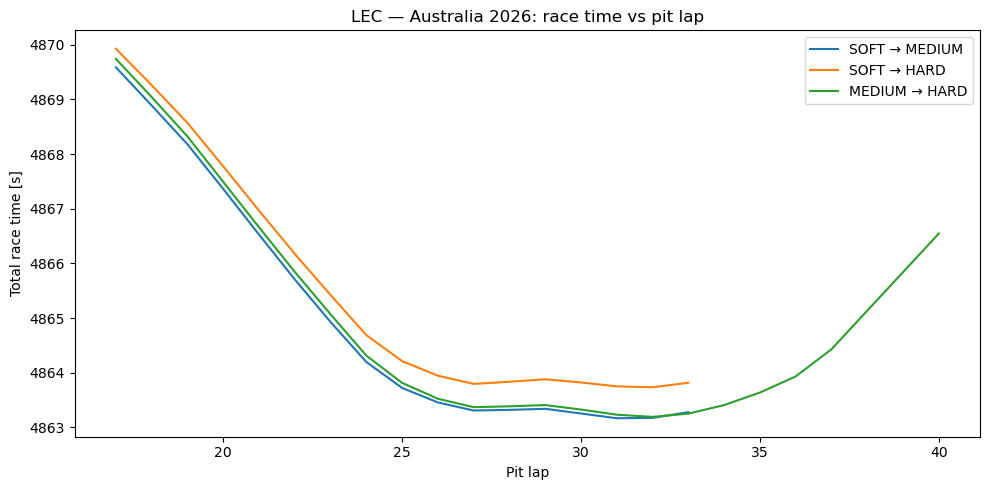

,strategy,best_pit_lap,total_s,gap_s
0,SOFT → MEDIUM,31,4863.2,0.0
2,MEDIUM → HARD,32,4863.2,0.0
1,SOFT → HARD,32,4863.7,0.6


In [7]:
aus_race = race_params('Australian Grand Prix')
fig, ax = plt.subplots(figsize=(10, 5))
rows = []
for compounds in COMPOUND_PAIRS:
    curve = pit_lap_curve('LEC', compounds, aus_race)
    if curve.empty:
        continue
    label = ' → '.join(compounds)
    ax.plot(curve.index, curve.values, label=label)
    rows.append({'strategy': label, 'best_pit_lap': curve.idxmin(), 'total_s': curve.min()})

ax.set_xlabel('Pit lap')
ax.set_ylabel('Total race time [s]')
ax.set_title('LEC — Australia 2026: race time vs pit lap')
ax.legend()
plt.tight_layout()
plt.show()

res = pd.DataFrame(rows).sort_values('total_s')
res['gap_s'] = res['total_s'] - res['total_s'].min()
res.round(1)

## 6. Monaco prediction

Monaco isn't in the dataset, so its race parameters are estimates: 78 laps, typical weather, and an average fuel-corrected lap of about 75 s. Only drivers with at least 150 clean laps are included.

In [8]:
MONACO = dict(total_laps=78, track_temp=38.0, air_temp=24.0, humidity=62.0, baseline=75.0)
MIN_LAPS = 150

laps_per_driver = df.groupby('Driver').size()
rows = []
for driver in sorted(laps_per_driver[laps_per_driver >= MIN_LAPS].index):
    best = None
    for compounds in COMPOUND_PAIRS:
        curve = pit_lap_curve(driver, compounds, MONACO)
        if not curve.empty and (best is None or curve.min() < best['total_s']):
            best = {'driver': driver, 'strategy': ' → '.join(compounds),
                    'pit_lap': curve.idxmin(), 'total_s': curve.min()}
    if best:
        rows.append(best)

ranking = pd.DataFrame(rows).sort_values('total_s').reset_index(drop=True)
ranking['gap_s'] = ranking['total_s'] - ranking['total_s'].iloc[0]
ranking.index += 1
ranking.round(1)

,driver,strategy,pit_lap,total_s,gap_s
1,ANT,MEDIUM → HARD,34,6000.5,0.0
2,RUS,MEDIUM → HARD,33,6018.1,17.6
3,NOR,MEDIUM → HARD,33,6025.9,25.3
4,HAM,MEDIUM → HARD,33,6040.2,39.7
5,LEC,MEDIUM → HARD,33,6041.8,41.2
6,VER,MEDIUM → HARD,38,6057.2,56.7
7,GAS,MEDIUM → HARD,33,6101.2,100.6
8,HAD,MEDIUM → HARD,34,6115.3,114.8
9,COL,MEDIUM → HARD,33,6123.2,122.7
10,BEA,MEDIUM → HARD,33,6123.7,123.2


## Limitations

- **No racing.** There is no traffic, overtaking or safety cars, which matter a lot at Monaco.
- **Little data.** The driver and team effects are learned from only five races.
- **Long stints.** Tree models can't extrapolate beyond the longest stints in the data, so very long stints look cheaper than they really are.
- **Rough constants.** The pit loss, the fuel effect and the Monaco parameters are general estimates, not measured per circuit.